# 01 · Exploratory analysis: field sales visits

Explores the FieldPulse field sales data (Apr–Sep 2026) through the cleaned and
analytics views in PostgreSQL. Each section answers one business question from
the README.

**Run it:** set `DATABASE_URL` to your PostgreSQL (e.g. Neon) after running
`data/load_postgres.py`, `sql/02_cleaning.sql` and `sql/03_views.sql`.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

url = os.environ["DATABASE_URL"].replace("postgresql://", "postgresql+psycopg://", 1)
engine = create_engine(url)

def q(sql: str) -> pd.DataFrame:
    return pd.read_sql(sql, engine)

# One accent for the point being made, gray for context, a muted line for targets.
ACCENT, HIGHLIGHT, CONTEXT, TARGET = "#2a78d6", "#eb6834", "#c3c2b7", "#898781"
plt.rcParams.update({
    "figure.figsize": (8, 3.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
})

## 0 · The data at a glance

In [2]:
q('''
SELECT 'stores' AS table_name, count(*) AS rows FROM clean.stores
UNION ALL SELECT 'visit plans', count(*) FROM raw.visit_plans
UNION ALL SELECT 'visits (after de-duplication)', count(*) FROM clean.visits
UNION ALL SELECT 'order lines', count(*) FROM raw.order_lines
''')

,table_name,rows
0,stores,480
1,visit plans,10238
2,visits (after de-duplication),8778
3,order lines,9017


In [3]:
stores = q("SELECT grade, channel, count(*) AS stores FROM clean.stores GROUP BY 1, 2")
stores.pivot(index="channel", columns="grade", values="stores").fillna(0).astype(int)

grade,A,B,C
channel,,,
Bar,13,25,34
Convenience,9,17,22
Grocery,24,57,63
Minimart,10,36,50
Restaurant,16,33,71


## 1 · Coverage: are stores visited as often as their grade requires?

Targets per month: A = 8 visits, B = 4, C = 2. Only valid visits count
(at the store, longer than 2 minutes).

In [4]:
cov = q('''
SELECT grade, round(avg(valid_visits), 2) AS avg_visits, max(required_visits) AS required,
       round(100 * avg(coverage_ratio), 1) AS coverage_pct,
       round(100 * avg(met_target::int), 1) AS pct_on_target
FROM analytics.store_month_coverage GROUP BY grade ORDER BY grade
''')
cov

,grade,avg_visits,required,coverage_pct,pct_on_target
0,A,6.45,8,80.4,24.3
1,B,3.24,4,79.8,43.2
2,C,1.72,2,81.2,67.1


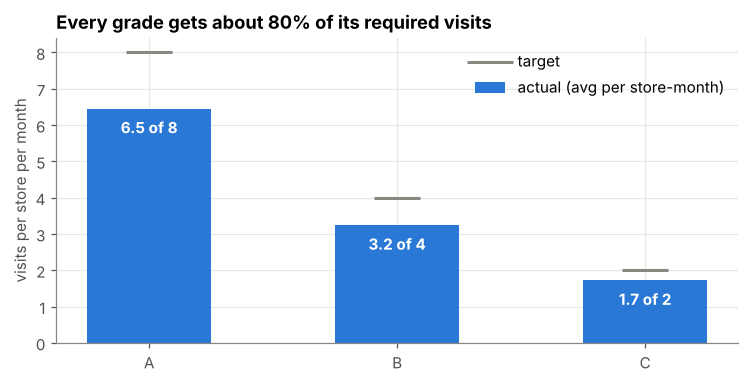

In [5]:
fig, ax = plt.subplots()
ax.bar(cov.grade, cov.avg_visits, color=ACCENT, width=0.5, label="actual (avg per store-month)")
ax.scatter(cov.grade, cov.required, color=TARGET, marker="_", s=900, linewidths=2, label="target", zorder=3)
for x, a, r in zip(cov.grade, cov.avg_visits, cov.required):
    ax.annotate(f"{a:.1f} of {r}", (x, a), xytext=(0, -16), textcoords="offset points", ha="center", color="white", fontweight="bold")
ax.set_title("Every grade gets about 80% of its required visits")
ax.set_ylabel("visits per store per month")
ax.legend(frameon=False, loc="upper right")
plt.show()

Coverage is about 80% for every grade, so A stores are not prioritised over C
stores. But the gap hurts most where the target is highest: only about a
quarter of A store-months hit 8 visits, against two-thirds of C store-months.

## 2 · Plan vs actual: how much of the approved plan gets done?

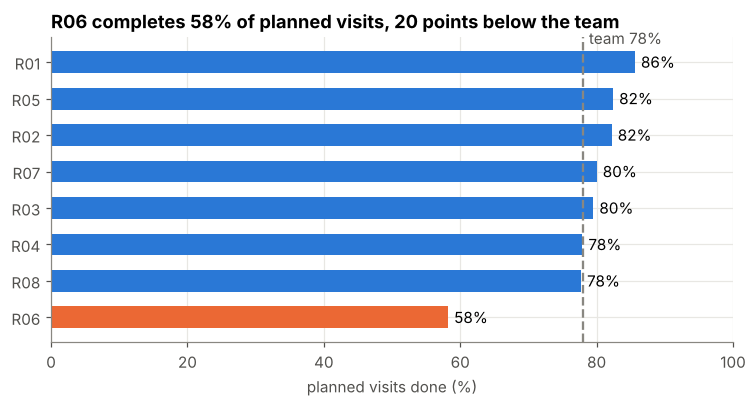

In [6]:
rep = q('''
SELECT rep_id, sum(planned) AS planned, sum(planned_done) AS done,
       round(100.0 * sum(planned_done) / sum(planned), 1) AS completion_pct
FROM analytics.rep_plan_vs_actual GROUP BY rep_id ORDER BY completion_pct
''')
team = 100 * rep.done.sum() / rep.planned.sum()

fig, ax = plt.subplots()
colors = [HIGHLIGHT if p < team - 10 else ACCENT for p in rep.completion_pct]
ax.barh(rep.rep_id, rep.completion_pct, color=colors, height=0.6)
ax.axvline(team, color=TARGET, linestyle="--", linewidth=1.5)
ax.annotate(f"team {team:.0f}%", (team, len(rep) - 0.5), xytext=(4, 0), textcoords="offset points", color="#52514e")
for y, p in enumerate(rep.completion_pct):
    ax.annotate(f"{p:.0f}%", (p, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 100)
ax.set_title("R06 completes 58% of planned visits, 20 points below the team")
ax.set_xlabel("planned visits done (%)")
plt.show()

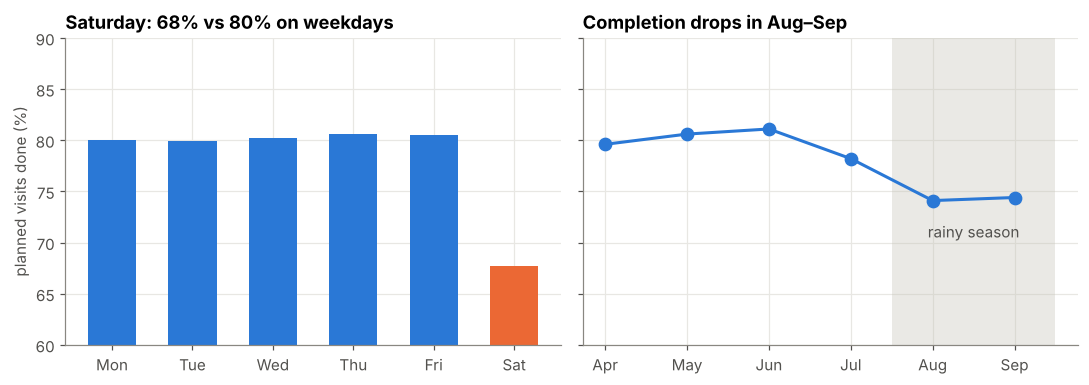

In [7]:
dow = q('''
SELECT extract(isodow FROM p.plan_date)::int AS dow, to_char(p.plan_date, 'Dy') AS weekday,
       round(100 * avg((EXISTS (SELECT 1 FROM clean.valid_visits v WHERE v.plan_id = p.plan_id))::int), 1) AS completion_pct
FROM raw.visit_plans p GROUP BY 1, 2 ORDER BY 1
''')
month = q('''
SELECT to_char(month, 'Mon') AS month, round(100.0 * sum(planned_done) / sum(planned), 1) AS completion_pct
FROM analytics.rep_plan_vs_actual GROUP BY analytics.rep_plan_vs_actual.month ORDER BY analytics.rep_plan_vs_actual.month
''')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
a1.bar(dow.weekday, dow.completion_pct, width=0.6,
       color=[HIGHLIGHT if d == "Sat" else ACCENT for d in dow.weekday])
a1.set_title("Saturday: 68% vs 80% on weekdays")
a1.set_ylabel("planned visits done (%)")
a2.plot(month.month, month.completion_pct, color=ACCENT, linewidth=2, marker="o", markersize=8)
a2.axvspan(3.5, 5.5, color=CONTEXT, alpha=0.35, linewidth=0)
a2.annotate("rainy season", (4.5, 70.5), ha="center", color="#52514e")
a2.set_title("Completion drops in Aug–Sep")
a2.set_ylim(60, 90)
a1.set_ylim(60, 90)
plt.tight_layout()
plt.show()

## 3 · Productivity: what does a field day look like?

In [8]:
prod = q('''
SELECT rep_id, round(avg(visits), 1) AS visits_per_day, to_char(avg(first_checkin), 'HH24:MI') AS first_checkin,
       to_char(avg(last_activity), 'HH24:MI') AS last_activity, round(avg(field_hours), 1) AS field_hours,
       round(sum(order_value_thb) / sum(visits)) AS thb_per_visit
FROM analytics.rep_daily_productivity GROUP BY rep_id ORDER BY visits_per_day DESC
''')
prod

,rep_id,visits_per_day,first_checkin,last_activity,field_hours,thb_per_visit
0,R01,8.4,09:16,14:28,5.2,2245.0
1,R05,8.0,09:17,14:04,4.8,1754.0
2,R02,8.0,09:18,14:14,4.9,2191.0
3,R04,7.7,09:19,14:06,4.8,2043.0
4,R07,7.7,09:13,13:53,4.7,1943.0
5,R03,7.6,09:16,13:47,4.5,1880.0
6,R08,7.5,09:17,13:56,4.6,2037.0
7,R06,5.6,09:19,12:41,3.4,2047.0


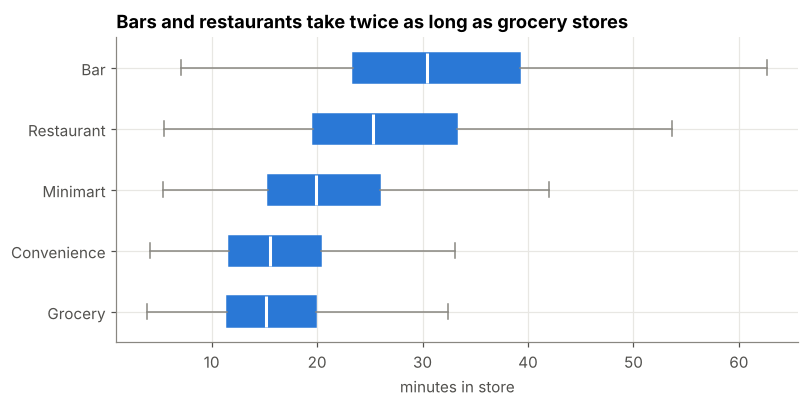

In [9]:
dur = q("SELECT channel, duration_min FROM analytics.visits_enriched WHERE is_valid AND duration_min IS NOT NULL")
order = dur.groupby("channel").duration_min.median().sort_values().index
fig, ax = plt.subplots()
ax.boxplot([dur.loc[dur.channel == c, "duration_min"] for c in order], tick_labels=order, orientation="horizontal",
           showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=ACCENT, color=ACCENT), medianprops=dict(color="white", linewidth=2),
           whiskerprops=dict(color=TARGET), capprops=dict(color=TARGET))
ax.set_title("Bars and restaurants take twice as long as grocery stores")
ax.set_xlabel("minutes in store")
plt.show()

Reps start around 09:15 and finish their last visit around 14:00, so a field
day is under 5 hours. R06 averages 5.6 visits a day against about 8 for the
others, and stops around 12:40.

## 4 · Data quality: how trustworthy is the visit data?

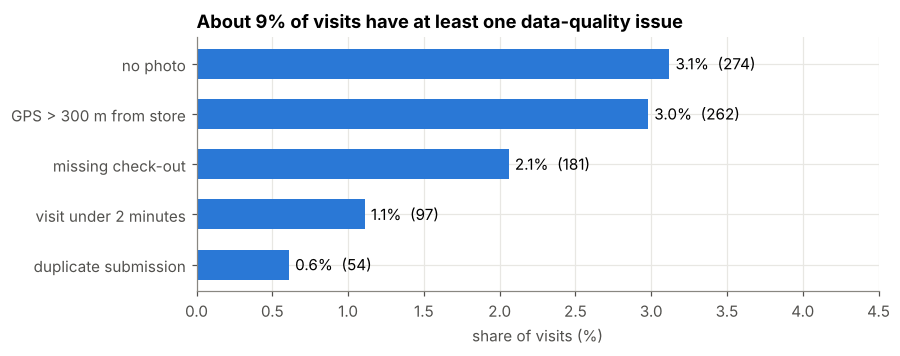

In [10]:
dq = q("SELECT issue, visits, round(100.0 * visits / out_of, 2) AS pct FROM clean.data_quality_summary ORDER BY pct")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(dq.issue, dq.pct, color=ACCENT, height=0.6)
for y, (p, n) in enumerate(zip(dq.pct, dq.visits)):
    ax.annotate(f"{p:.1f}%  ({n})", (p, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_title("About 9% of visits have at least one data-quality issue")
ax.set_xlabel("share of visits (%)")
ax.set_xlim(0, 4.5)
plt.show()

In [11]:
q('''
SELECT round(100 * avg((flag_gps_far OR flag_missing_checkout OR coalesce(flag_too_short, false) OR flag_no_photo)::int), 1)
       AS pct_visits_with_any_issue
FROM clean.visits
''')

,pct_visits_with_any_issue
0,9.0


## 5 · Distributor stock: where does stock run out?

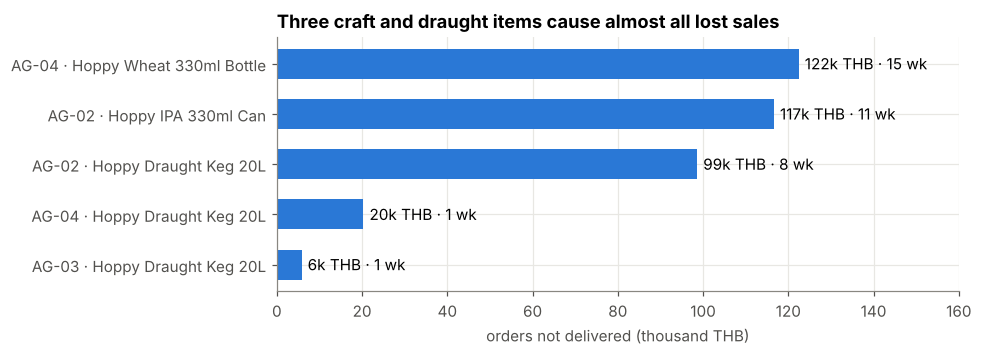

In [12]:
so = q('''
SELECT agent_id || ' · ' || sku_name AS item, count(*) FILTER (WHERE is_stockout) AS stockout_weeks,
       sum(lost_value_thb) AS lost_thb
FROM analytics.stock_weekly GROUP BY agent_id, sku_name
HAVING sum(lost_value_thb) > 0 ORDER BY lost_thb
''')
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(so.item, so.lost_thb / 1000, color=ACCENT, height=0.6)
for y, (v, w) in enumerate(zip(so.lost_thb, so.stockout_weeks)):
    ax.annotate(f"{v/1000:,.0f}k THB · {w} wk", (v / 1000, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_title("Three craft and draught items cause almost all lost sales")
ax.set_xlabel("orders not delivered (thousand THB)")
ax.set_xlim(0, 160)
plt.show()

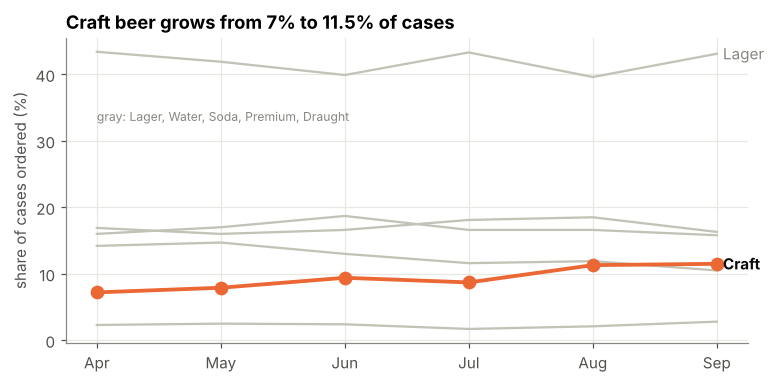

In [13]:
cat = q('''
SELECT visit_month, category, round(100.0 * sum(cases) / sum(sum(cases)) OVER (PARTITION BY visit_month), 1) AS share
FROM analytics.sales_lines GROUP BY 1, 2 ORDER BY 1
''').pivot(index="visit_month", columns="category", values="share")
fig, ax = plt.subplots()
cat.index = pd.to_datetime(cat.index).strftime("%b")
for c in cat.columns:
    if c != "Craft":
        ax.plot(cat.index, cat[c], color=CONTEXT, linewidth=1.5)
ax.annotate("Lager", (cat.index[-1], cat["Lager"].iloc[-1]), xytext=(4, 0), textcoords="offset points",
            va="center", color="#898781")
ax.annotate("gray: Lager, Water, Soda, Premium, Draught", (0, 33), color="#898781", fontsize=8)
ax.plot(cat.index, cat["Craft"], color=HIGHLIGHT, linewidth=2.5, marker="o", markersize=8)
ax.annotate("Craft", (cat.index[-1], cat["Craft"].iloc[-1]), xytext=(4, 0), textcoords="offset points",
            va="center", color="#0b0b0b", fontweight="bold")
ax.set_title("Craft beer grows from 7% to 11.5% of cases")
ax.set_ylabel("share of cases ordered (%)")
plt.show()

Craft beer's share keeps growing, but the distributors that run out of stock
most are out of exactly the craft and draught SKUs. Stock planning has not
caught up with demand.

## 6 · What would closing the A-store gap be worth?

In [14]:
q('''
WITH v AS (SELECT grade, avg(order_value_thb) AS thb_per_visit FROM analytics.visits_enriched WHERE is_valid GROUP BY grade),
     g AS (SELECT grade, sum(greatest(required_visits - valid_visits, 0)) AS missed_visits
           FROM analytics.store_month_coverage GROUP BY grade)
SELECT grade, missed_visits, round(thb_per_visit) AS thb_per_visit,
       round(missed_visits * thb_per_visit) AS potential_thb
FROM g JOIN v USING (grade) ORDER BY grade
''')

,grade,missed_visits,thb_per_visit,potential_thb
0,A,672.0,3762.0,2528155.0
1,B,793.0,1566.0,1242233.0
2,C,533.0,728.0,387852.0


**Takeaways**

1. Coverage sits around 80% for every grade; A stores, worth about 5x a C-store
   visit, are not protected when reps fall behind.
2. One rep (R06) explains a large share of the gap: 58% plan completion and the
   shortest field days.
3. Saturdays and the rainy season are when planned visits get dropped.
4. About 9% of visits carry a data-quality issue; GPS checks and a mandatory
   check-out would remove most of them.
5. Craft demand is growing while two distributors keep running out of craft and
   draught SKUs.